[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BASE-Laboratory/OpenImpala/blob/master/tutorials/01_getting_started.ipynb)

# Steady-State Diffusion and 3D Field Inspection

Steady-state diffusive or conductive transport through a porous phase $\Omega_p \subset [0, L_x] \times [0, L_y] \times [0, L_z]$ is governed by Laplace's equation with insulating pore–solid walls,

$$\nabla \cdot (D_0 \nabla \phi) = 0 \quad \text{in } \Omega_p, \qquad \nabla \phi \cdot \mathbf{n} = 0 \quad \text{on } \partial \Omega_{ps},$$

subject to fixed potentials $\phi = 0$ and $\phi = 1$ on opposing inlet and outlet planes and zero-flux conditions on the four lateral faces. From the integrated boundary flux $J$, the normalised effective diffusivity and tortuosity factor follow as

$$\frac{D_{\text{eff}}}{D_0} = \frac{|J|\,L}{A\,\Delta \phi} = \frac{\varepsilon}{\tau},$$

where $\varepsilon = |\Omega_p| / |\Omega|$ is the conducting volume fraction.

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip install -q openimpala matplotlib

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import openimpala as oi

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

## Analytical Verification on Parallel Slabs

Before analysing tomographic data, verify the discretisation on a geometry with a closed-form solution: alternating conducting (`phase=1`) and insulating (`phase=0`) slabs aligned with the $z$-axis. Because every streamline runs straight from $z = 0$ to $z = L_z$ without lateral deflection, $\varepsilon = 0.5$, $D_{\text{eff}}/D_0 = 0.5$, and $\tau = 1$ identically.

In standalone MPI scripts, wrap solver calls in `with oi.Session():` to initialise and finalise the AMReX runtime deterministically (interactive notebooks also start a session automatically on first call).

In [3]:
slabs = np.zeros((32, 32, 32), dtype=np.int32)
slabs[:, :, :16] = 1  # conducting half-space spanning z (axis 0)

with oi.Session():
    slab_res = oi.tortuosity(slabs, phase=1, direction="z")

assert np.isclose(slab_res.tortuosity, 1.0, rtol=1e-6)
slab_res

Metric,Value
Tortuosity,1.000000
Effective diffusivity,5.000000e-01
Solver status,converged
Iterations,0
Residual norm,0.00e+00
Flux in,-1.600000e+01
Flux out,-1.600000e+01
Active VF,0.500000


## Loading Segmented Tomographic Data

OpenImpala's 3D arrays follow `(Nz, Ny, Nx)` axis ordering (`z` = axis 0, `y` = axis 1, `x` = axis 2) to match TIFF page stacks and HDF5 hyperslabs. Here we load the $64^3$ two-phase porous ceramic/electrode subvolume shipped in `openimpala.datasets` via `oi.read_image()`, assigning a physical voxel pitch of $h = 0.5\;\mu\mathrm{m}$ ($32 \times 32 \times 32\;\mu\mathrm{m}^3$ domain).

In [4]:
tiff_path = oi.datasets.fetch_path("SampleData_2Phase_squared.tif")
_, img = oi.read_image(tiff_path, voxel_size=0.5)

vf = oi.volume_fraction(img, phase=1)
vf

Metric,Value
Phase count,"104,681"
Total count,"262,144"
Volume fraction,0.399326 (39.93%)


Check whether `phase=1` forms a continuous face-connected pathway between the two $z$-boundaries before assembling the linear system:

In [5]:
perc = oi.percolation_check(img, phase=1, direction="z")
perc

Metric,Value
Direction,Z
Percolates,Yes
Active VF,0.397034


## Solving for Tortuosity and the 3D Potential Field

Passing `return_field=True` returns the converged 3D cell-centred potential $\phi \in [0, 1]$ on `res.solution_field` alongside the scalar transport diagnostics. Inactive solid cells carry `0.0`.

In [6]:
res = oi.tortuosity(img, phase=1, direction="z", return_field=True)
res

Metric,Value
Tortuosity,3.397745
Effective diffusivity,1.168521e-01
Solver status,converged
Iterations,653
Residual norm,9.69e-10
Flux in,-3.739268e+00
Flux out,-3.739268e+00
Active VF,0.397034


At steady state, mass conservation requires the integrated inlet and outlet fluxes to balance up to the Krylov solver tolerance:

In [7]:
rel_flux_imbalance = abs(abs(res.flux_in) - abs(res.flux_out)) / abs(res.flux_in)
print(f"Inlet / outlet flux imbalance: {rel_flux_imbalance:.2e}")

Inlet / outlet flux imbalance: 4.20e-09


## Inspecting Local Potential Gradients and Bottlenecks

Differentiating $\phi$ inside the conducting phase highlights the contrast between narrow pore throats—where $|\nabla \phi|$ spikes and dominates macroscopic transport resistance—and dead-end pockets that sit at nearly uniform potential with negligible flux.

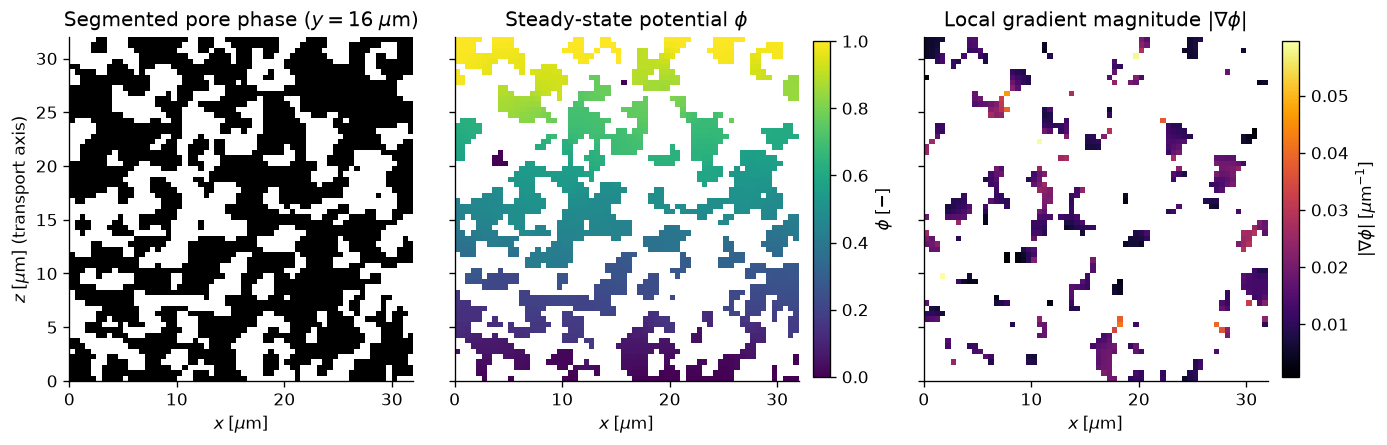

In [8]:
vol = oi.datasets.two_phase_cubic()
h_um = 0.5
phi = np.where(vol == 1, res.solution_field, np.nan)

# Central differences inside interior pore cells (masked to NaN adjacent to solid walls)
gz, gy, gx = np.gradient(phi, h_um)
flux_mag = np.sqrt(gx**2 + gy**2 + gz**2)

mid_y = vol.shape[1] // 2
extent_xz = [0.0, vol.shape[2] * h_um, 0.0, vol.shape[0] * h_um]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.6), sharey=True, constrained_layout=True)

axes[0].imshow(vol[:, mid_y, :], origin="lower", extent=extent_xz, cmap="binary_r")
axes[0].set_title(rf"Segmented pore phase ($y = {mid_y * h_um:.0f}\;\mu$m)")
axes[0].set_xlabel(r"$x\;[\mu\mathrm{m}]$")
axes[0].set_ylabel(r"$z\;[\mu\mathrm{m}]$ (transport axis)")

im_phi = axes[1].imshow(
    phi[:, mid_y, :], origin="lower", extent=extent_xz, cmap="viridis", vmin=0.0, vmax=1.0
)
axes[1].set_title(r"Steady-state potential $\phi$")
axes[1].set_xlabel(r"$x\;[\mu\mathrm{m}]$")
fig.colorbar(im_phi, ax=axes[1], fraction=0.046, pad=0.04, label=r"$\phi\;[-]$")

im_j = axes[2].imshow(flux_mag[:, mid_y, :], origin="lower", extent=extent_xz, cmap="inferno")
axes[2].set_title(r"Local gradient magnitude $|\nabla \phi|$")
axes[2].set_xlabel(r"$x\;[\mu\mathrm{m}]$")
fig.colorbar(im_j, ax=axes[2], fraction=0.046, pad=0.04, label=r"$|\nabla \phi|\;[\mu\mathrm{m}^{-1}]$")

plt.show()

## References

1. N. Epstein, *On tortuosity and the tortuosity factor in flow and diffusion through porous media*, Chem. Eng. Sci. **44**(3), 777–779 (1989).
2. B. Tjaden, S. J. Cooper, D. J. L. Brett, D. Kramer, and P. R. Shearing, *On the origin and application of the Bruggeman correlation for analysing transport phenomena in electrochemical systems*, Curr. Opin. Chem. Eng. **12**, 44–51 (2016).